# W1 - MovieLens EDA

数据集：ml-latest-small（约 10 万条评分）。本 notebook 产出 W1 PPT 的 4 张图。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path(r"C:\Users\LEGION\PycharmProjects\multi-agent-search\data\ml-latest-small")

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

ratings = pd.read_csv(DATA / "ratings.csv")
movies  = pd.read_csv(DATA / "movies.csv")

print(f"评分条数: {len(ratings):,}")
print(f"用户数:   {ratings.userId.nunique():,}")
print(f"电影数:   {ratings.movieId.nunique():,}")
print(f"矩阵稀疏度: {1 - len(ratings) / (ratings.userId.nunique() * ratings.movieId.nunique()):.2%}")
ratings.head()

评分条数: 100,836
用户数:   610
电影数:   9,724
矩阵稀疏度: 98.30%


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 图1 评分值分布

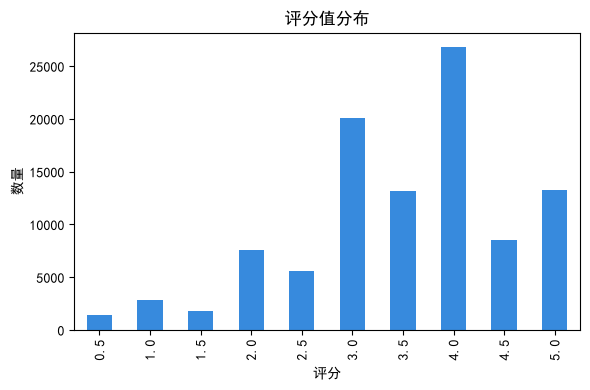

In [2]:
ratings["rating"].value_counts().sort_index().plot(
    kind="bar", figsize=(6, 4), color="#378ADD")
plt.title("评分值分布")
plt.xlabel("评分"); plt.ylabel("数量")
plt.tight_layout(); plt.show()

## 图2 每用户评分数量分布（长尾，W3 聚类动机）

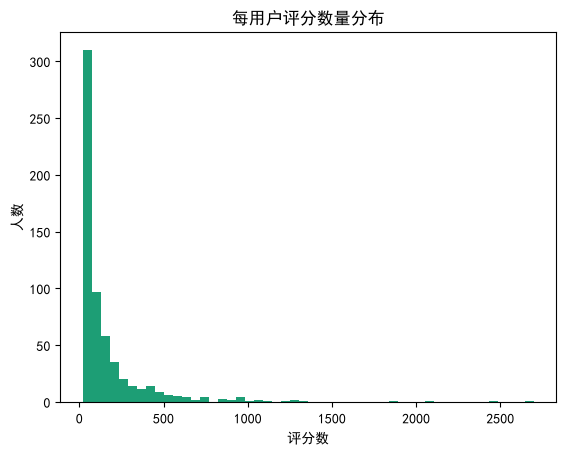

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

In [3]:
per_user = ratings.groupby("userId").size()
plt.hist(per_user, bins=50, color="#1D9E75")
plt.title("每用户评分数量分布")
plt.xlabel("评分数"); plt.ylabel("人数")
plt.show()
per_user.describe()

## 图3 Top10 高分电影（至少 50 人评过）

In [4]:
per_movie = ratings.groupby("movieId")["rating"].agg(["count", "mean"])
top = (per_movie[per_movie["count"] >= 50]
       .nlargest(10, "mean")
       .reset_index()
       .merge(movies[["movieId", "title"]], on="movieId"))
top[["title", "count", "mean"]]

,title,count,mean
0,"Shawshank Redemption, The (1994)",317,4.429022
1,"Godfather, The (1972)",192,4.289062
2,Fight Club (1999),218,4.272936
3,Cool Hand Luke (1967),57,4.271930
4,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.268041
5,Rear Window (1954),84,4.261905
6,"Godfather: Part II, The (1974)",129,4.259690
7,"Departed, The (2006)",107,4.252336
8,Goodfellas (1990),126,4.250000
9,Casablanca (1942),100,4.240000


## 图4 电影类型分布 Top15

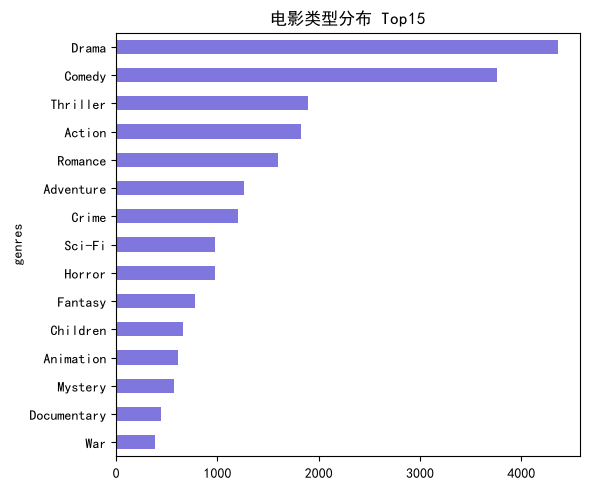

In [5]:
genres = movies["genres"].str.split("|").explode()
genres.value_counts().head(15).sort_values().plot(
    kind="barh", figsize=(6, 5), color="#7F77DD")
plt.title("电影类型分布 Top15")
plt.tight_layout(); plt.show()